In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [21]:
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Classes:", iris.target_names)

Dataset shape: (150, 4)
Target shape: (150,)
Classes: ['setosa' 'versicolor' 'virginica']


In [22]:
df = pd.DataFrame(X, columns=iris.feature_names)
df["target"] = y

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [23]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [24]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


In [25]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("First 5 normalized samples:")
print(X_scaled[:5])

First 5 normalized samples:
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


In [26]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("First 5 normalized samples:")
print(X_scaled[:5])

First 5 normalized samples:
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 120
Testing samples: 30


In [28]:
def create_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(4,)),
        tf.keras.layers.Dense(16, activation='relu'),
        tf.keras.layers.Dense(8, activation='relu'),
        tf.keras.layers.Dense(3, activation='softmax')
    ])

    return model

In [29]:
def train_model(learning_rate, epochs):

    model = create_model()

    optimizer = tf.keras.optimizers.SGD(
        learning_rate=learning_rate
    )

    loss_function = tf.keras.losses.SparseCategoricalCrossentropy()

    X_train_tf = tf.convert_to_tensor(
        X_train,
        dtype=tf.float32
    )

    y_train_tf = tf.convert_to_tensor(
        y_train,
        dtype=tf.int64
    )

    history = {
        "loss": [],
        "accuracy": []
    }

    for epoch in range(epochs):

        # Forward propagation
        with tf.GradientTape() as tape:

            predictions = model(
                X_train_tf,
                training=True
            )

            loss = loss_function(
                y_train_tf,
                predictions
            )

        # Backpropagation
        gradients = tape.gradient(
            loss,
            model.trainable_variables
        )

        # Update weights
        optimizer.apply_gradients(
            zip(gradients, model.trainable_variables)
        )

        # Calculate training accuracy
        predicted_classes = tf.argmax(
            predictions,
            axis=1,
            output_type=tf.int64
        )

        accuracy = tf.reduce_mean(
            tf.cast(
                predicted_classes == y_train_tf,
                tf.float32
            )
        )

        history["loss"].append(float(loss))
        history["accuracy"].append(float(accuracy))

    return model, history

In [30]:
model, history = train_model(
    learning_rate=0.01,
    epochs=50
)

In [31]:
X_test_tf = tf.convert_to_tensor(
    X_test,
    dtype=tf.float32
)

test_predictions = model(
    X_test_tf,
    training=False
)

test_classes = tf.argmax(
    test_predictions,
    axis=1,
    output_type=tf.int64
).numpy()

test_accuracy = accuracy_score(
    y_test,
    test_classes
)

print("Test Accuracy:", test_accuracy)

Test Accuracy: 0.8333333333333334


In [32]:
learning_rates = [0.001, 0.01, 0.1]

learning_rate_results = []

for lr in learning_rates:

    model, history = train_model(
        learning_rate=lr,
        epochs=50
    )

    predictions = model(
        tf.convert_to_tensor(X_test, dtype=tf.float32),
        training=False
    )

    predicted_classes = tf.argmax(
        predictions,
        axis=1,
        output_type=tf.int64
    ).numpy()

    accuracy = accuracy_score(
        y_test,
        predicted_classes
    )

    learning_rate_results.append({
        "Learning Rate": lr,
        "Epochs": 50,
        "Test Accuracy": accuracy
    })

lr_results_df = pd.DataFrame(learning_rate_results)

lr_results_df

,Learning Rate,Epochs,Test Accuracy
0,0.001,50,0.633333
1,0.010,50,0.766667
2,0.100,50,0.866667


In [33]:
epoch_values = [10, 30, 50, 100]

epoch_results = []

for epochs in epoch_values:

    model, history = train_model(
        learning_rate=0.01,
        epochs=epochs
    )

    predictions = model(
        tf.convert_to_tensor(X_test, dtype=tf.float32),
        training=False
    )

    predicted_classes = tf.argmax(
        predictions,
        axis=1,
        output_type=tf.int64
    ).numpy()

    accuracy = accuracy_score(
        y_test,
        predicted_classes
    )

    epoch_results.append({
        "Learning Rate": 0.01,
        "Epochs": epochs,
        "Test Accuracy": accuracy
    })

epoch_results_df = pd.DataFrame(epoch_results)

epoch_results_df

,Learning Rate,Epochs,Test Accuracy
0,0.01,10,0.700000
1,0.01,30,0.333333
2,0.01,50,0.366667
3,0.01,100,0.633333


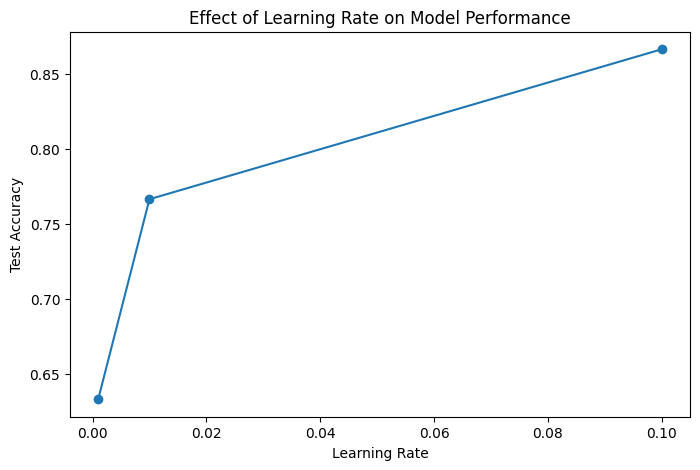

In [34]:
plt.figure(figsize=(8, 5))

plt.plot(
    lr_results_df["Learning Rate"],
    lr_results_df["Test Accuracy"],
    marker="o"
)

plt.xlabel("Learning Rate")
plt.ylabel("Test Accuracy")
plt.title("Effect of Learning Rate on Model Performance")

plt.show()

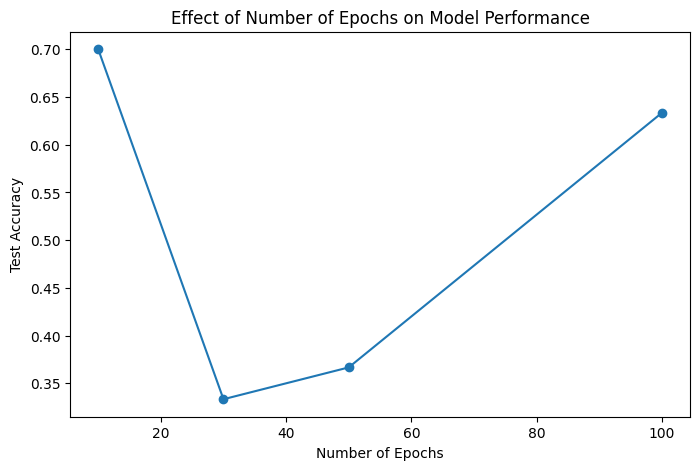

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(
    epoch_results_df["Epochs"],
    epoch_results_df["Test Accuracy"],
    marker="o"
)

plt.xlabel("Number of Epochs")
plt.ylabel("Test Accuracy")
plt.title("Effect of Number of Epochs on Model Performance")

plt.show()